# Лабораторная работа №1. Метод k ближайших соседей (KNN)

Датасет: [Anime Dataset 2023](https://www.kaggle.com/datasets/dbdmobile/myanimelist-dataset) - данные примерно о 25 тыс. аниме с сайта MyAnimeList.

На нем решаю две задачи:
- классификация: предсказание возрастного рейтинга тайтла (G, PG, PG-13, R, R+)
- регрессия: предсказание оценки тайтла на MAL (Score)

Импорт библиотек. random_state фиксирую, чтобы результаты не менялись от запуска к запуску.

In [1]:
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, f_regression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay,
                             mean_absolute_error, root_mean_squared_error, r2_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

## 1. Выбор начальных условий

### 1.1. Выбор датасета

Я выбрал датасет Anime Dataset 2023 с Kaggle. Он собран с сайта MyAnimeList, в нем около 25 тыс. тайтлов и 24 колонки: жанры, тип (TV, фильм, OVA и т.д.), первоисточник (манга, ранобэ и т.д.), студии, длительность серии, даты выхода, количество зрителей, оценка и другие. Этот датасет больше никто в потоке не взял (проверял по общей таблице).

Задача классификации - предсказывать возрастной рейтинг тайтла. На стриминговых сервисах у каждого тайтла должен быть возрастной рейтинг, от него зависит родительский контроль и попадет ли тайтл в детский раздел. Новые тайтлы часто добавляются без рейтинга, и его приходится ставить вручную, а модель могла бы делать это автоматически или хотя бы подсказывать модератору.

Задача регрессии - предсказывать оценку тайтла (Score). Оценка показывает, насколько тайтл понравился зрителям. Если ее можно предсказать по характеристикам тайтла и статистике зрителей, то сервису это поможет решать, стоит ли покупать лицензию на тайтл и продвигать его, а также рекомендовать тайтлы, у которых пока мало оценок.

### 1.2. Загрузка и анализ данных

Скачиваю с Kaggle только файл anime-dataset-2023.csv, остальные файлы в датасете - это оценки пользователей, они весят несколько гигабайт и здесь не нужны.

In [2]:
path = kagglehub.dataset_download("dbdmobile/myanimelist-dataset", path="anime-dataset-2023.csv")
df = pd.read_csv(path)
print(df.shape)
df.head(3)

(24905, 24)


,anime_id,Name,English name,Other name,Score,Genres,Synopsis,Type,Episodes,Aired,Premiered,Status,Producers,Licensors,Studios,Source,Duration,Rating,Rank,Popularity,Favorites,Scored By,Members,Image URL
0,1,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,8.75,"Action, Award Winning, Sci-Fi","Crime is timeless. By the year 2071, humanity ...",TV,26.0,"Apr 3, 1998 to Apr 24, 1999",spring 1998,Finished Airing,Bandai Visual,"Funimation, Bandai Entertainment",Sunrise,Original,24 min per ep,R - 17+ (violence & profanity),41.0,43,78525,914193.0,1771505,https://cdn.myanimelist.net/images/anime/4/196...
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop: The Movie,カウボーイビバップ 天国の扉,8.38,"Action, Sci-Fi","Another day, another bounty—such is the life o...",Movie,1.0,"Sep 1, 2001",UNKNOWN,Finished Airing,"Sunrise, Bandai Visual",Sony Pictures Entertainment,Bones,Original,1 hr 55 min,R - 17+ (violence & profanity),189.0,602,1448,206248.0,360978,https://cdn.myanimelist.net/images/anime/1439/...
2,6,Trigun,Trigun,トライガン,8.22,"Action, Adventure, Sci-Fi","Vash the Stampede is the man with a $$60,000,0...",TV,26.0,"Apr 1, 1998 to Sep 30, 1998",spring 1998,Finished Airing,Victor Entertainment,"Funimation, Geneon Entertainment USA",Madhouse,Manga,24 min per ep,PG-13 - Teens 13 or older,328.0,246,15035,356739.0,727252,https://cdn.myanimelist.net/images/anime/7/203...


Посмотрим на типы колонок:

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24905 entries, 0 to 24904
Data columns (total 24 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   anime_id      24905 non-null  int64
 1   Name          24905 non-null  str  
 2   English name  24905 non-null  str  
 3   Other name    24905 non-null  str  
 4   Score         24905 non-null  str  
 5   Genres        24905 non-null  str  
 6   Synopsis      24905 non-null  str  
 7   Type          24905 non-null  str  
 8   Episodes      24905 non-null  str  
 9   Aired         24905 non-null  str  
 10  Premiered     24905 non-null  str  
 11  Status        24905 non-null  str  
 12  Producers     24905 non-null  str  
 13  Licensors     24905 non-null  str  
 14  Studios       24905 non-null  str  
 15  Source        24905 non-null  str  
 16  Duration      24905 non-null  str  
 17  Rating        24905 non-null  str  
 18  Rank          24905 non-null  str  
 19  Popularity    24905 non-null  int64


Некоторые числовые колонки прочитались как строки, потому что пропуски в датасете записаны как UNKNOWN. Заменяю UNKNOWN на NaN, перевожу эти колонки в числа и считаю процент пропусков по колонкам.

In [4]:
df = df.replace("UNKNOWN", np.nan)
for col in ["Score", "Episodes", "Rank", "Popularity", "Favorites", "Scored By", "Members"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

(df.isna().mean() * 100).round(1).sort_values(ascending=False)

Licensors       81.0
Premiered       77.9
English name    58.5
Producers       53.6
Studios         42.3
Score           37.0
Scored By       37.0
Genres          19.8
Rank            18.5
Rating           2.7
Episodes         2.5
Other name       0.5
Type             0.3
Members          0.0
Favorites        0.0
Popularity       0.0
anime_id         0.0
Duration         0.0
Source           0.0
Name             0.0
Status           0.0
Aired            0.0
Synopsis         0.0
Image URL        0.0
dtype: float64

Больше всего пропусков в Licensors, Premiered, English name и Producers, их использовать не буду (год выхода можно взять из Aired, там пропусков нет). У 37% тайтлов нет оценки, для регрессии их придется выкинуть. Жанры не указаны у 20% тайтлов, студии у 42%.

Rank и Popularity - это места тайтла в рейтинге MAL по оценке и по популярности. Проверим их корреляцию Спирмена со Score и Members:

In [5]:
df[["Score", "Rank", "Members", "Popularity"]].corr(method="spearman").round(3)

,Score,Rank,Members,Popularity
Score,1.00,-1.000,0.730,-0.730
Rank,-1.00,1.000,-0.817,0.872
Members,0.73,-0.817,1.000,-0.955
Popularity,-0.73,0.872,-0.955,1.000


Rank полностью определяется оценкой (корреляция -1), то есть это просто номер тайтла по Score, и для регрессии это была бы утечка целевой переменной. Popularity почти полностью определяется Members (-0.955), новой информации в ней нет. Поэтому обе колонки дальше не использую.

Целевая переменная для классификации - колонка Rating. Сразу оставляю в ней только короткие обозначения рейтингов (G, PG, PG-13 и т.д.):

In [6]:
df["Rating"] = df["Rating"].str.split(" - ").str[0]
df["Rating"].value_counts(dropna=False)

Rating
PG-13    8502
G        7660
PG       4050
Rx       1475
R        1414
R+       1135
NaN       669
Name: count, dtype: int64

Похоже, что рейтинг Rx (18+) совпадает с жанром Hentai, проверим:

In [7]:
pd.crosstab(df["Rating"], df["Genres"].str.contains("Hentai", na=False))

Genres,False,True
Rating,,
G,7660,0
PG,4050,0
PG-13,8502,0
R,1414,0
R+,1123,12
Rx,2,1473


Rx совпадает с этим жанром в 1473 случаях из 1475, то есть класс просто повторяет признак и предсказывать его нет смысла. Поэтому класс Rx убираю, тайтлы без рейтинга тоже. Остается 5 классов: G, PG, PG-13, R, R+.

Для регрессии беру все тайтлы, у которых есть оценка.

In [8]:
df_clf = df[df["Rating"].notna() & (df["Rating"] != "Rx")].copy()
df_clf["target"] = df_clf["Rating"]
df_reg = df[df["Score"].notna()].copy()

print("Классификация:", df_clf.shape)
print("Регрессия:", df_reg.shape)

Классификация: (22761, 25)
Регрессия: (15692, 24)


Посмотрим на распределение целевых переменных:

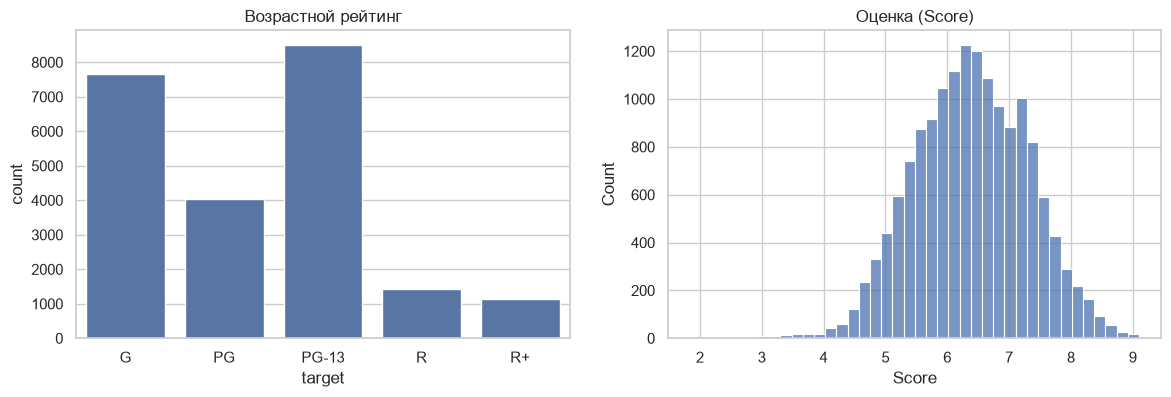

target
PG-13    0.374
G        0.337
PG       0.178
R        0.062
R+       0.050
Name: proportion, dtype: float64
count    15692.00
mean         6.38
std          0.93
min          1.85
25%          5.73
50%          6.39
75%          7.06
max          9.10
Name: Score, dtype: float64


In [9]:
rating_order = ["G", "PG", "PG-13", "R", "R+"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(x=df_clf["target"], order=rating_order, ax=axes[0])
axes[0].set_title("Возрастной рейтинг")
sns.histplot(df_reg["Score"], bins=40, ax=axes[1])
axes[1].set_title("Оценка (Score)")
plt.show()

print(df_clf["target"].value_counts(normalize=True).round(3))
print(df_reg["Score"].describe().round(2))

Классы несбалансированные: на PG-13 и G приходится 71% тайтлов, а на R и R+ всего 6% и 5%. Оценка распределена примерно нормально: среднее 6.38, стандартное отклонение 0.93, минимум 1.85, максимум 9.1.

### 1.3. Выбор метрик

Для классификации основная метрика - macro-F1. Классы несбалансированные, а угадывать нужно все рейтинги, в том числе редкие R и R+ (если взрослый тайтл попадет в детский раздел, это плохо). macro-F1 считает F1 для каждого класса и усредняет, поэтому редкие классы влияют на нее так же, как частые. Еще смотрю accuracy, ее проще понять (доля правильных ответов), но при дисбалансе она может быть высокой, даже если редкие классы вообще не угадываются.

Для регрессии основная метрика - MAE, это средняя ошибка в баллах оценки. Ее легко интерпретировать (например, "в среднем ошибаемся на 0.4 балла"), и она меньше реагирует на выбросы. Дополнительно смотрю RMSE, она сильнее штрафует большие ошибки, и R2 - долю объясненной дисперсии, по ней удобно сравнивать модели.

Делю данные на train и test в соотношении 80/20, для классификации со стратификацией по классам. Test использую только для финальной оценки, а гипотезы и параметры проверяю кросс-валидацией на train. Сохраняю индексы строк, чтобы потом брать из df любые признаки для тех же объектов.

In [10]:
idx_train_clf, idx_test_clf = train_test_split(df_clf.index, test_size=0.2, stratify=df_clf["target"],
                                               random_state=RANDOM_STATE)
idx_train_reg, idx_test_reg = train_test_split(df_reg.index, test_size=0.2, random_state=RANDOM_STATE)

y_train_clf, y_test_clf = df_clf.loc[idx_train_clf, "target"], df_clf.loc[idx_test_clf, "target"]
y_train_reg, y_test_reg = df_reg.loc[idx_train_reg, "Score"], df_reg.loc[idx_test_reg, "Score"]

print("Классификация: train", len(idx_train_clf), "test", len(idx_test_clf))
print("Регрессия: train", len(idx_train_reg), "test", len(idx_test_reg))

Классификация: train 18208 test 4553
Регрессия: train 12553 test 3139


## 2. Бейзлайн

В качестве бейзлайна беру KNeighborsClassifier и KNeighborsRegressor из sklearn с параметрами по умолчанию (k=5, евклидово расстояние, одинаковые веса). Признаки - только те, которые уже есть в таблице в виде чисел: Episodes, Members, Favorites, Scored By, для классификации еще Score. Пропуски заполняю медианой, больше никакой обработки нет.

In [11]:
base_features_clf = ["Score", "Episodes", "Members", "Favorites", "Scored By"]
base_features_reg = ["Episodes", "Members", "Favorites", "Scored By"]

baseline_clf = make_pipeline(SimpleImputer(strategy="median"), KNeighborsClassifier())
baseline_clf.fit(df.loc[idx_train_clf, base_features_clf], y_train_clf)

baseline_reg = make_pipeline(SimpleImputer(strategy="median"), KNeighborsRegressor())
baseline_reg.fit(df.loc[idx_train_reg, base_features_reg], y_train_reg)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('kneighborsregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Episodes','Members','Favorites','Scored By']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"cop

Функции для подсчета метрик. Результаты всех моделей буду складывать в словари results_clf и results_reg.

In [12]:
def clf_metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "f1_macro": f1_score(y_true, y_pred, average="macro")}


def reg_metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": root_mean_squared_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}


results_clf = {}
results_reg = {}

Качество бейзлайна на тесте:

In [13]:
pred_base_clf = baseline_clf.predict(df.loc[idx_test_clf, base_features_clf])
pred_base_reg = baseline_reg.predict(df.loc[idx_test_reg, base_features_reg])

results_clf["sklearn бейзлайн"] = clf_metrics(y_test_clf, pred_base_clf)
results_reg["sklearn бейзлайн"] = reg_metrics(y_test_reg, pred_base_reg)

display(pd.DataFrame(results_clf).T.round(4))
display(pd.DataFrame(results_reg).T.round(4))

,accuracy,f1_macro
sklearn бейзлайн,0.5834,0.3986


,MAE,RMSE,R2
sklearn бейзлайн,0.5186,0.6805,0.4553


Метрики по классам:

In [14]:
print(classification_report(y_test_clf, pred_base_clf, digits=3))

              precision    recall  f1-score   support

           G      0.578     0.727     0.644      1532
          PG      0.656     0.544     0.595       810
       PG-13      0.582     0.634     0.607      1701
           R      0.263     0.053     0.088       283
          R+      0.178     0.035     0.059       227

    accuracy                          0.583      4553
   macro avg      0.451     0.399     0.399      4553
weighted avg      0.554     0.583     0.558      4553



Бейзлайн получился слабым. В классификации accuracy 0.583, но macro-F1 всего 0.399: G, PG и PG-13 модель еще как-то различает, а R и R+ почти не угадывает (F1 0.088 и 0.059, recall 5% и 4%). В регрессии средняя ошибка 0.52 балла, R2 = 0.455.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

1. H1. Масштабирование признаков. KNN считает расстояния, а признаки в разных масштабах: Members доходит до миллионов, а Score от 1 до 10. Без масштабирования расстояние по сути считается только по Members и Scored By. Попробую StandardScaler.
2. H2. Логарифмирование. У Members, Favorites, Scored By и Episodes очень длинные хвосты (у нескольких тайтлов миллионы зрителей, у большинства тысячи). После логарифма распределения станут ровнее.
3. H3. Новые признаки из категориальных и текстовых колонок: жанры (one-hot, жанров у тайтла может быть несколько), тип, первоисточник, длительность серии в минутах (из строк типа "24 min per ep") и год выхода (из Aired). Для регрессии еще добавлю возрастной рейтинг. Жанры должны сильно помочь в классификации, например Ecchi или Horror явно указывают на взрослый рейтинг.
4. H4. Относительные признаки: fav_rate = Favorites / Members (какая доля зрителей добавила тайтл в избранное) и scored_rate = Scored By / Members (какая доля поставила оценку). Если тайтл часто добавляют в избранное, то, скорее всего, он хороший.
5. H5. Студии. One-hot для 20 самых частых студий (беру основную студию, первую в списке). Многие студии работают на определенную аудиторию.
6. H6. Отбор признаков. После H3-H5 признаков будет 50-80, а для KNN лишние признаки - это шум в расстоянии (проклятие размерности). Попробую оставлять только k лучших признаков по F-статистике (SelectKBest).
7. H7. Подбор гиперпараметров на кросс-валидации: число соседей, веса (uniform или distance) и метрика (манхэттенская или евклидова).

Гипотезы проверяю по очереди кросс-валидацией на train (5 фолдов). Если гипотеза улучшила основную метрику (macro-F1 или MAE), оставляю ее и следующую проверяю уже вместе с ней.

### 3.2. Визуализация и новые признаки

Распределение Members до и после логарифма (к гипотезе H2):

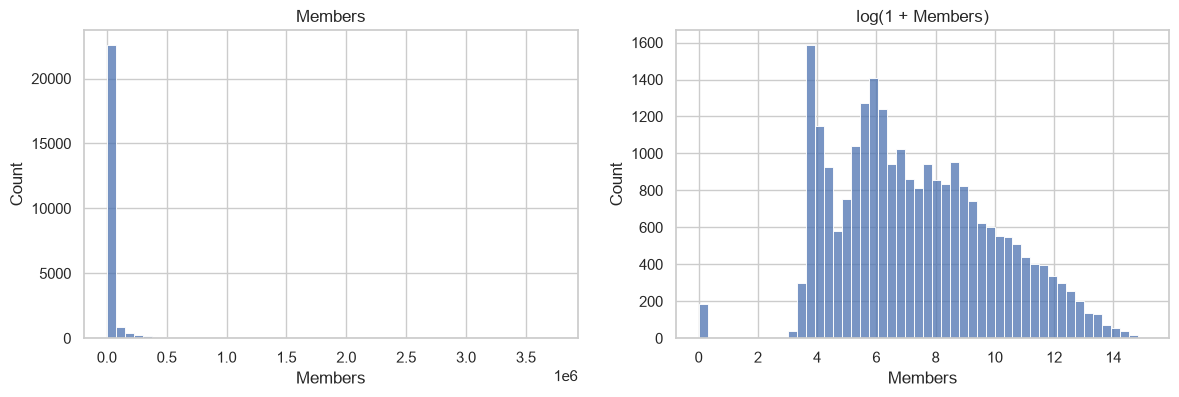

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Members"], bins=50, ax=axes[0])
axes[0].set_title("Members")
sns.histplot(np.log1p(df["Members"]), bins=50, ax=axes[1])
axes[1].set_title("log(1 + Members)")
plt.show()

Без логарифма почти все тайтлы попадают в первый столбик, а после логарифма распределение похоже на нормальное.

Создаю новые признаки: логарифмы, длительность серии в минутах, год выхода и относительные признаки.

In [16]:
def duration_to_min(s):
    if pd.isna(s):
        return np.nan
    hours = re.search(r"(\d+) hr", s)
    minutes = re.search(r"(\d+) min", s)
    seconds = re.search(r"(\d+) sec", s)
    total = 0
    if hours:
        total += int(hours.group(1)) * 60
    if minutes:
        total += int(minutes.group(1))
    if seconds:
        total += int(seconds.group(1)) / 60
    return total if total > 0 else np.nan


for col in ["Episodes", "Members", "Favorites", "Scored By"]:
    df["log_" + col] = np.log1p(df[col])

df["duration_min"] = df["Duration"].apply(duration_to_min)
df["year"] = df["Aired"].str.extract(r"(\d{4})")[0].astype(float)
df["fav_rate"] = df["Favorites"] / df["Members"].replace(0, np.nan)
df["scored_rate"] = df["Scored By"] / df["Members"].replace(0, np.nan)

df[["Duration", "duration_min", "Aired", "year", "fav_rate", "scored_rate"]].head()

,Duration,duration_min,Aired,year,fav_rate,scored_rate
0,24 min per ep,24.0,"Apr 3, 1998 to Apr 24, 1999",1998.0,0.044327,0.516054
1,1 hr 55 min,115.0,"Sep 1, 2001",2001.0,0.004011,0.571359
2,24 min per ep,24.0,"Apr 1, 1998 to Sep 30, 1998",1998.0,0.020674,0.490530
3,25 min per ep,25.0,"Jul 3, 2002 to Dec 25, 2002",2002.0,0.005477,0.382638
4,23 min per ep,23.0,"Sep 30, 2004 to Sep 29, 2005",2004.0,0.000933,0.427505


One-hot кодирование жанров, типа, первоисточника, рейтинга (он будет признаком для регрессии) и топ-20 студий.

In [17]:
genres = df["Genres"].str.get_dummies(sep=", ").add_prefix("genre_")
types = pd.get_dummies(df["Type"], prefix="type", dtype=int)
sources = pd.get_dummies(df["Source"], prefix="source", dtype=int)
ratings = pd.get_dummies(df["Rating"], prefix="rating", dtype=int)

main_studio = df["Studios"].str.split(", ").str[0]
top_studios = main_studio.value_counts().head(20).index
studios = pd.get_dummies(main_studio.where(main_studio.isin(top_studios)), prefix="studio", dtype=int)

df = pd.concat([df, genres, types, sources, ratings, studios], axis=1)

genre_cols, type_cols, source_cols = list(genres.columns), list(types.columns), list(sources.columns)
rating_cols, studio_cols = list(ratings.columns), list(studios.columns)
print("жанров:", len(genre_cols), "типов:", len(type_cols), "источников:", len(source_cols),
      "рейтингов:", len(rating_cols), "студий:", len(studio_cols))

жанров: 21 типов: 6 источников: 17 рейтингов: 6 студий: 20


Какая доля тайтлов каждого рейтинга относится к каждому жанру (к гипотезе H3):

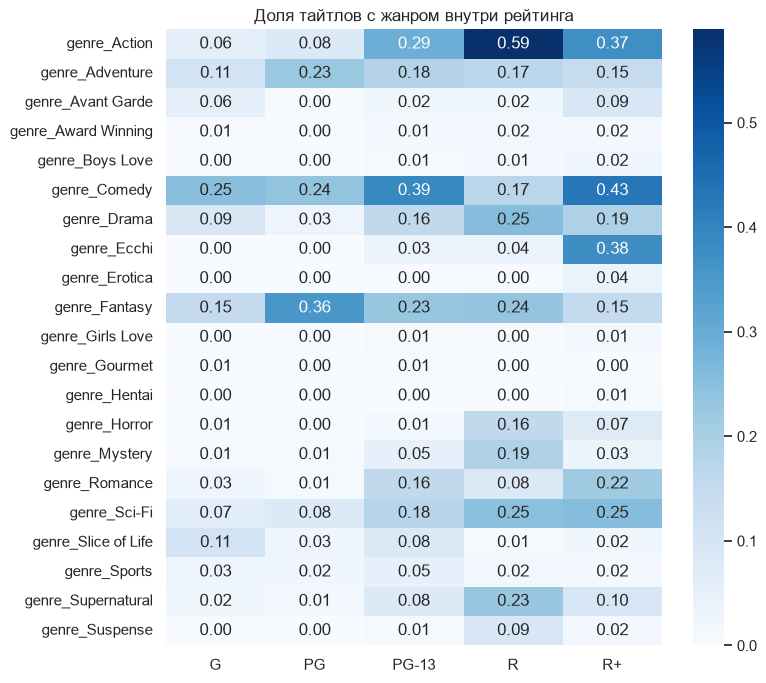

In [18]:
genre_share = df.loc[df_clf.index, genre_cols].groupby(df_clf["target"]).mean().loc[rating_order]

plt.figure(figsize=(8, 8))
sns.heatmap(genre_share.T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Доля тайтлов с жанром внутри рейтинга")
plt.xlabel("")
plt.show()

Видно, что жанры сильно отличаются по рейтингам. Ecchi есть у 38% тайтлов R+ и почти не встречается у остальных, Horror, Mystery, Supernatural и Suspense чаще всего у R, Action у R и R+, у PG больше всего Fantasy и Adventure, а Slice of Life чаще всего у G. Значит, жанры должны помочь (H3).

Корреляция числовых признаков с оценкой (к гипотезам H2 и H4):

In [19]:
check_cols = ["Score", "Members", "log_Members", "Favorites", "log_Favorites",
              "fav_rate", "scored_rate", "duration_min", "year"]
df.loc[df_reg.index, check_cols].corr()["Score"].round(3)

Score            1.000
Members          0.391
log_Members      0.707
Favorites        0.235
log_Favorites    0.730
fav_rate         0.509
scored_rate      0.151
duration_min     0.312
year             0.233
Name: Score, dtype: float64

После логарифма корреляция с оценкой сильно выросла: у Members с 0.391 до 0.707, у Favorites с 0.235 до 0.730. fav_rate тоже неплохо коррелирует с оценкой (0.509).

### 3.3. Проверка гипотез

Функции для проверки гипотез: считают метрики KNN кросс-валидацией на train (5 фолдов). Пайплайн: заполнение пропусков медианой, масштабирование, отбор признаков (если нужен) и KNN.

In [20]:
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_knn_pipeline(model, scale=True, select=None):
    steps = [SimpleImputer(strategy="median")]
    if scale:
        steps.append(StandardScaler())
    if select is not None:
        steps.append(select)
    steps.append(model)
    return make_pipeline(*steps)


def check_clf(features, scale=True, select_k=None, n_neighbors=5, weights="uniform", p=2):
    select = SelectKBest(f_classif, k=select_k) if select_k else None
    model = make_knn_pipeline(KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, p=p), scale, select)
    scores = cross_validate(model, df.loc[idx_train_clf, features], y_train_clf, cv=cv_clf,
                            scoring=["f1_macro", "accuracy"], n_jobs=-1)
    res = {"f1_macro": scores["test_f1_macro"].mean(),
           "f1_std": scores["test_f1_macro"].std(),
           "accuracy": scores["test_accuracy"].mean()}
    print(f"Классификация ({len(features)} признаков, отбор: {select_k or 'нет'}): "
          f"macro-F1 = {res['f1_macro']:.4f} +/- {res['f1_std']:.4f}, accuracy = {res['accuracy']:.4f}")
    return res


def check_reg(features, scale=True, select_k=None, n_neighbors=5, weights="uniform", p=2):
    select = SelectKBest(f_regression, k=select_k) if select_k else None
    model = make_knn_pipeline(KNeighborsRegressor(n_neighbors=n_neighbors, weights=weights, p=p), scale, select)
    scores = cross_validate(model, df.loc[idx_train_reg, features], y_train_reg, cv=cv_reg,
                            scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"], n_jobs=-1)
    res = {"MAE": -scores["test_neg_mean_absolute_error"].mean(),
           "MAE_std": scores["test_neg_mean_absolute_error"].std(),
           "RMSE": -scores["test_neg_root_mean_squared_error"].mean(),
           "R2": scores["test_r2"].mean()}
    print(f"Регрессия ({len(features)} признаков, отбор: {select_k or 'нет'}): "
          f"MAE = {res['MAE']:.4f} +/- {res['MAE_std']:.4f}, RMSE = {res['RMSE']:.4f}, R2 = {res['R2']:.4f}")
    return res


cv_history_clf = {}
cv_history_reg = {}

Сначала считаю бейзлайн на кросс-валидации, чтобы было с чем сравнивать.

In [21]:
cv_history_clf["бейзлайн"] = check_clf(base_features_clf, scale=False)
cv_history_reg["бейзлайн"] = check_reg(base_features_reg, scale=False)

Классификация (5 признаков, отбор: нет): macro-F1 = 0.3840 +/- 0.0087, accuracy = 0.5825


Регрессия (4 признаков, отбор: нет): MAE = 0.5217 +/- 0.0042, RMSE = 0.6852, R2 = 0.4571


На кросс-валидации у бейзлайна macro-F1 = 0.384 и MAE = 0.522, примерно как на тесте.

#### H1. Масштабирование

In [22]:
features_clf = base_features_clf
features_reg = base_features_reg
cv_history_clf["H1"] = check_clf(features_clf)
cv_history_reg["H1"] = check_reg(features_reg)

Классификация (5 признаков, отбор: нет): macro-F1 = 0.4044 +/- 0.0047, accuracy = 0.5794
Регрессия (4 признаков, отбор: нет): MAE = 0.4687 +/- 0.0036, RMSE = 0.6265, R2 = 0.5463


Масштабирование помогло в обеих задачах: macro-F1 выросла с 0.384 до 0.404, MAE уменьшилась с 0.522 до 0.469. H1 подтвердилась, дальше всегда масштабирую признаки.

#### H2. Логарифмирование

In [23]:
log_features = ["log_Episodes", "log_Members", "log_Favorites", "log_Scored By"]
features_clf = ["Score"] + log_features
features_reg = log_features
cv_history_clf["H2"] = check_clf(features_clf)
cv_history_reg["H2"] = check_reg(features_reg)

Классификация (5 признаков, отбор: нет): macro-F1 = 0.4203 +/- 0.0073, accuracy = 0.5911


Регрессия (4 признаков, отбор: нет): MAE = 0.4543 +/- 0.0057, RMSE = 0.6099, R2 = 0.5700


Логарифм тоже помог: macro-F1 с 0.404 до 0.420, MAE с 0.469 до 0.454. H2 подтвердилась.

#### H3. Признаки из категориальных и текстовых колонок

In [24]:
new_features = ["duration_min", "year"] + genre_cols + type_cols + source_cols
features_clf = features_clf + new_features
features_reg = features_reg + new_features + rating_cols
cv_history_clf["H3"] = check_clf(features_clf)
cv_history_reg["H3"] = check_reg(features_reg)

Классификация (51 признаков, отбор: нет): macro-F1 = 0.5821 +/- 0.0130, accuracy = 0.6731


Регрессия (56 признаков, отбор: нет): MAE = 0.4356 +/- 0.0064, RMSE = 0.5839, R2 = 0.6058


В классификации самый большой прирост: macro-F1 с 0.420 до 0.582, то есть рейтинг в основном зависит от жанров и типа тайтла. В регрессии MAE с 0.454 до 0.436. H3 подтвердилась для обеих задач.

#### H4. Относительные признаки

In [25]:
rate_features = ["fav_rate", "scored_rate"]
cv_history_clf["H4"] = check_clf(features_clf + rate_features)
cv_history_reg["H4"] = check_reg(features_reg + rate_features)

Классификация (53 признаков, отбор: нет): macro-F1 = 0.5798 +/- 0.0132, accuracy = 0.6730


Регрессия (58 признаков, отбор: нет): MAE = 0.4200 +/- 0.0063, RMSE = 0.5625, R2 = 0.6341


Для регрессии относительные признаки помогли: MAE с 0.436 до 0.420, R2 с 0.606 до 0.634. Для классификации macro-F1 немного упала (с 0.582 до 0.580), разница меньше разброса по фолдам, но лучше точно не стало. H4 принимаю только для регрессии.

#### H5. Студии

In [26]:
features_reg = features_reg + rate_features
cv_history_clf["H5"] = check_clf(features_clf + studio_cols)
cv_history_reg["H5"] = check_reg(features_reg + studio_cols)

Классификация (71 признаков, отбор: нет): macro-F1 = 0.5979 +/- 0.0081, accuracy = 0.6797


Регрессия (78 признаков, отбор: нет): MAE = 0.4310 +/- 0.0068, RMSE = 0.5762, R2 = 0.6161


Для классификации студии помогли: macro-F1 с 0.582 до 0.598, а в регрессии MAE стала хуже (с 0.420 до 0.431). H5 принимаю только для классификации. Видимо, по студии можно понять целевую аудиторию тайтла, но не его качество, поэтому в регрессии 20 новых признаков только добавляют шум в расстояние.

#### H6. Отбор признаков

Пробую оставлять разное количество признаков:

In [27]:
features_clf = features_clf + studio_cols
print("Признаков сейчас: классификация", len(features_clf), "регрессия", len(features_reg))

select_clf = {}
select_reg = {}
for k in [10, 15, 20, 30, 40]:
    select_clf[k] = check_clf(features_clf, select_k=k)
    select_reg[k] = check_reg(features_reg, select_k=k)

Признаков сейчас: классификация 71 регрессия 58


Классификация (71 признаков, отбор: 10): macro-F1 = 0.5188 +/- 0.0082, accuracy = 0.6311
Регрессия (58 признаков, отбор: 10): MAE = 0.4139 +/- 0.0074, RMSE = 0.5636, R2 = 0.6328


Классификация (71 признаков, отбор: 15): macro-F1 = 0.5567 +/- 0.0195, accuracy = 0.6499


Регрессия (58 признаков, отбор: 15): MAE = 0.3866 +/- 0.0069, RMSE = 0.5249, R2 = 0.6813


Классификация (71 признаков, отбор: 20): macro-F1 = 0.5680 +/- 0.0127, accuracy = 0.6575


Регрессия (58 признаков, отбор: 20): MAE = 0.3962 +/- 0.0068, RMSE = 0.5349, R2 = 0.6692


Классификация (71 признаков, отбор: 30): macro-F1 = 0.5920 +/- 0.0123, accuracy = 0.6792


Регрессия (58 признаков, отбор: 30): MAE = 0.4042 +/- 0.0106, RMSE = 0.5445, R2 = 0.6571


Классификация (71 признаков, отбор: 40): macro-F1 = 0.5886 +/- 0.0101, accuracy = 0.6781


Регрессия (58 признаков, отбор: 40): MAE = 0.4140 +/- 0.0074, RMSE = 0.5560, R2 = 0.6425


Для регрессии отбор признаков сильно помог: при 15 признаках MAE 0.387 вместо 0.420 на всех 58. Для классификации лучше оставить все признаки, с отбором macro-F1 только падает (лучший вариант 0.592 при k=30, без отбора 0.598). H6 принимаю только для регрессии, точное число признаков подберу вместе с гиперпараметрами.

In [28]:
cv_history_clf["H6"] = select_clf[30]
cv_history_reg["H6"] = select_reg[15]

#### H7. Подбор гиперпараметров

GridSearchCV по числу соседей, весам и метрике (p=1 - манхэттенское расстояние, p=2 - евклидово). Сначала классификация:

In [29]:
grid_clf = GridSearchCV(
    make_knn_pipeline(KNeighborsClassifier()),
    {"kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
     "kneighborsclassifier__weights": ["uniform", "distance"],
     "kneighborsclassifier__p": [1, 2]},
    cv=cv_clf, scoring="f1_macro", n_jobs=-1)
grid_clf.fit(df.loc[idx_train_clf, features_clf], y_train_clf)
print(grid_clf.best_params_)
print("macro-F1 на CV:", round(grid_clf.best_score_, 4))

{'kneighborsclassifier__n_neighbors': 11, 'kneighborsclassifier__p': 1, 'kneighborsclassifier__weights': 'distance'}
macro-F1 на CV: 0.6268


Для регрессии заодно подбираю число признаков в SelectKBest:

In [30]:
grid_reg = GridSearchCV(
    make_knn_pipeline(KNeighborsRegressor(), select=SelectKBest(f_regression)),
    {"selectkbest__k": [10, 12, 15, 18, 20, 25, 30, 35, 40],
     "kneighborsregressor__n_neighbors": [5, 7, 10, 15, 20, 30],
     "kneighborsregressor__weights": ["uniform", "distance"],
     "kneighborsregressor__p": [1, 2]},
    cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1)
grid_reg.fit(df.loc[idx_train_reg, features_reg], y_train_reg)
print(grid_reg.best_params_)
print("MAE на CV:", round(-grid_reg.best_score_, 4))

{'kneighborsregressor__n_neighbors': 10, 'kneighborsregressor__p': 1, 'kneighborsregressor__weights': 'distance', 'selectkbest__k': 30}
MAE на CV: 0.3685


Считаю все метрики на кросс-валидации для лучших параметров и смотрю, какие признаки отобрались для регрессии:

In [31]:
best_knn_clf = grid_clf.best_estimator_.named_steps["kneighborsclassifier"]
best_knn_reg = grid_reg.best_estimator_.named_steps["kneighborsregressor"]
best_select_k = grid_reg.best_estimator_.named_steps["selectkbest"].k

cv_history_clf["H7"] = check_clf(features_clf, n_neighbors=best_knn_clf.n_neighbors,
                                 weights=best_knn_clf.weights, p=best_knn_clf.p)
cv_history_reg["H7"] = check_reg(features_reg, select_k=best_select_k, n_neighbors=best_knn_reg.n_neighbors,
                                 weights=best_knn_reg.weights, p=best_knn_reg.p)

selected = grid_reg.best_estimator_.named_steps["selectkbest"].get_support()
print(list(np.array(features_reg)[selected]))

Классификация (71 признаков, отбор: нет): macro-F1 = 0.6268 +/- 0.0077, accuracy = 0.7093


Регрессия (58 признаков, отбор: 30): MAE = 0.3685 +/- 0.0104, RMSE = 0.4985, R2 = 0.7126
[np.str_('log_Episodes'), np.str_('log_Members'), np.str_('log_Favorites'), np.str_('log_Scored By'), np.str_('duration_min'), np.str_('year'), np.str_('genre_Action'), np.str_('genre_Adventure'), np.str_('genre_Avant Garde'), np.str_('genre_Award Winning'), np.str_('genre_Drama'), np.str_('genre_Fantasy'), np.str_('genre_Hentai'), np.str_('genre_Mystery'), np.str_('genre_Romance'), np.str_('genre_Supernatural'), np.str_('type_Music'), np.str_('type_ONA'), np.str_('type_TV'), np.str_('source_Light novel'), np.str_('source_Manga'), np.str_('source_Music'), np.str_('source_Original'), np.str_('source_Unknown'), np.str_('rating_G'), np.str_('rating_PG-13'), np.str_('rating_R'), np.str_('rating_Rx'), np.str_('fav_rate'), np.str_('scored_rate')]


Лучшие параметры для классификации: k=11, манхэттенское расстояние, веса distance, macro-F1 выросла с 0.598 до 0.627. Для регрессии: k=10, манхэттенское расстояние, веса distance и 30 признаков, MAE уменьшилась с 0.3866 до 0.3685. H7 подтвердилась. С манхэттенским расстоянием для регрессии лучше оказалось оставлять 30 признаков, а не 15. Отобрались все числовые признаки (логарифмы, длительность, год, относительные признаки) и часть жанров, типов, источников и рейтингов.

График качества от числа соседей (при лучших весах и метрике):

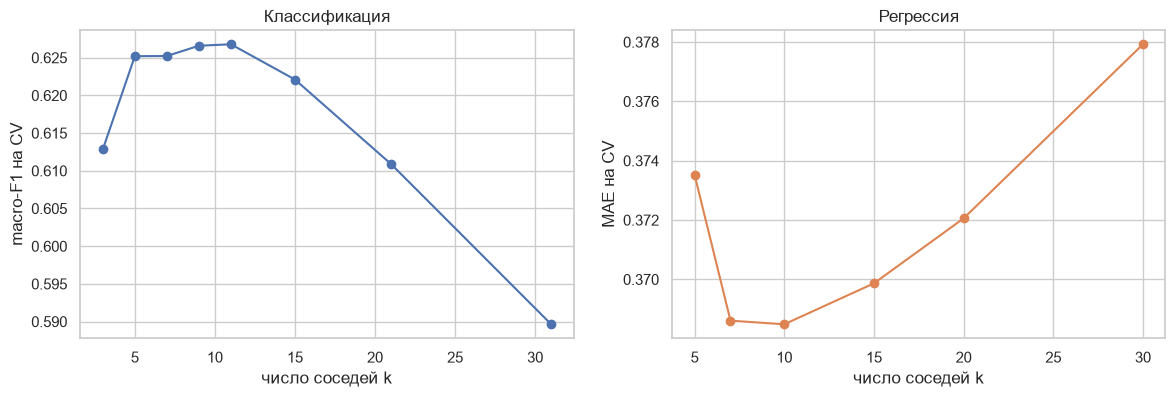

{3: 0.6128, 5: 0.6252, 7: 0.6252, 9: 0.6266, 11: 0.6268, 15: 0.6221, 21: 0.6109, 31: 0.5896}
{5: 0.3735, 7: 0.3686, 10: 0.3685, 15: 0.3699, 20: 0.3721, 30: 0.3779}


In [32]:
res_clf = pd.DataFrame(grid_clf.cv_results_)
res_reg = pd.DataFrame(grid_reg.cv_results_)

curve_clf = res_clf[(res_clf["param_kneighborsclassifier__weights"] == best_knn_clf.weights)
                    & (res_clf["param_kneighborsclassifier__p"] == best_knn_clf.p)]
curve_reg = res_reg[(res_reg["param_kneighborsregressor__weights"] == best_knn_reg.weights)
                    & (res_reg["param_kneighborsregressor__p"] == best_knn_reg.p)
                    & (res_reg["param_selectkbest__k"] == best_select_k)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(curve_clf["param_kneighborsclassifier__n_neighbors"].astype(int), curve_clf["mean_test_score"], marker="o")
axes[0].set_xlabel("число соседей k")
axes[0].set_ylabel("macro-F1 на CV")
axes[0].set_title("Классификация")
axes[1].plot(curve_reg["param_kneighborsregressor__n_neighbors"].astype(int), -curve_reg["mean_test_score"], marker="o", color="C1")
axes[1].set_xlabel("число соседей k")
axes[1].set_ylabel("MAE на CV")
axes[1].set_title("Регрессия")
plt.show()

print(dict(zip(curve_clf["param_kneighborsclassifier__n_neighbors"].astype(int), curve_clf["mean_test_score"].round(4))))
print(dict(zip(curve_reg["param_kneighborsregressor__n_neighbors"].astype(int), (-curve_reg["mean_test_score"]).round(4))))

При маленьком k модель слишком зависит от отдельных соседей (при k=3 macro-F1 0.613), а при большом слишком все усредняет (при k=31 - 0.590). Лучше всего k=9-11, но от 5 до 15 метрика меняется мало. В регрессии примерно так же: MAE меньше всего при k=7-10 (0.3686 и 0.3685) и растет как при k=5 (0.3735), так и при больших k (0.3779 при k=30).

Как менялась основная метрика по гипотезам (серые столбцы - гипотезы, которые не приняты):

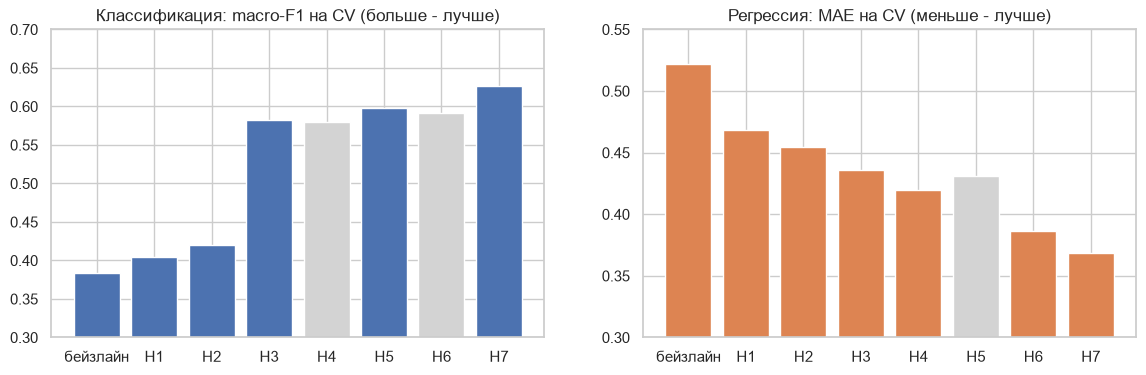

In [33]:
steps = ["бейзлайн", "H1", "H2", "H3", "H4", "H5", "H6", "H7"]
rejected_clf = ["H4", "H6"]
rejected_reg = ["H5"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(steps, [cv_history_clf[s]["f1_macro"] for s in steps],
            color=["lightgray" if s in rejected_clf else "C0" for s in steps])
axes[0].set_ylim(0.3, 0.7)
axes[0].set_title("Классификация: macro-F1 на CV (больше - лучше)")
axes[1].bar(steps, [cv_history_reg[s]["MAE"] for s in steps],
            color=["lightgray" if s in rejected_reg else "C1" for s in steps])
axes[1].set_ylim(0.3, 0.55)
axes[1].set_title("Регрессия: MAE на CV (меньше - лучше)")
plt.show()

### 3.4. Улучшенный бейзлайн

По итогам проверки гипотез улучшенный бейзлайн получился такой:
- классификация: масштабирование (H1), логарифмы (H2), жанры, тип, первоисточник, длительность и год (H3), топ-20 студий (H5), KNN с k=11, манхэттенским расстоянием и весами distance (H7)
- регрессия: масштабирование (H1), логарифмы (H2), жанры, тип, первоисточник, длительность, год и рейтинг (H3), относительные признаки (H4), отбор 30 лучших признаков (H6), KNN с k=10, манхэттенским расстоянием и весами distance (H7)

GridSearchCV после подбора уже обучил лучшие модели на всем train, их и проверяю на тесте.

In [34]:
improved_clf = grid_clf.best_estimator_
improved_reg = grid_reg.best_estimator_

pred_impr_clf = improved_clf.predict(df.loc[idx_test_clf, features_clf])
pred_impr_reg = improved_reg.predict(df.loc[idx_test_reg, features_reg])

results_clf["sklearn улучшенный"] = clf_metrics(y_test_clf, pred_impr_clf)
results_reg["sklearn улучшенный"] = reg_metrics(y_test_reg, pred_impr_reg)

print(classification_report(y_test_clf, pred_impr_clf, digits=3))

              precision    recall  f1-score   support

           G      0.702     0.783     0.740      1532
          PG      0.787     0.742     0.764       810
       PG-13      0.716     0.754     0.735      1701
           R      0.714     0.371     0.488       283
          R+      0.573     0.361     0.443       227

    accuracy                          0.718      4553
   macro avg      0.699     0.602     0.634      4553
weighted avg      0.717     0.718     0.712      4553



Матрица ошибок (по строкам доли от реального класса):

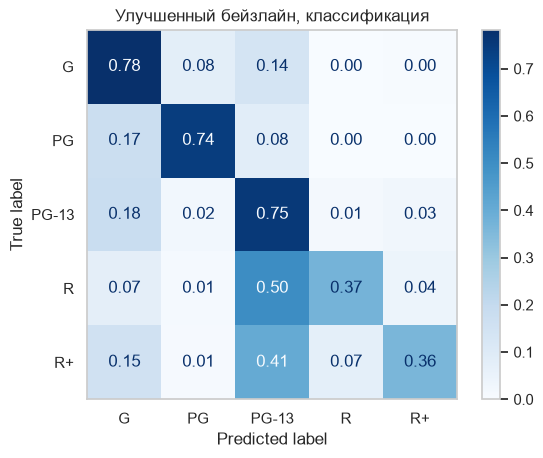

In [35]:
ConfusionMatrixDisplay.from_predictions(y_test_clf, pred_impr_clf, labels=rating_order, normalize="true",
                                        values_format=".2f", cmap="Blues")
plt.title("Улучшенный бейзлайн, классификация")
plt.grid(False)
plt.show()

По сравнению с бейзлайном F1 для R и R+ выросла с 0.09 и 0.06 до 0.49 и 0.44, но эти классы все равно угадываются хуже всего: половину R и 41% R+ модель относит к PG-13. Хуже всего, когда взрослый тайтл получает G, так бывает у 7% тайтлов R и у 15% тайтлов R+. В обратную сторону модель почти не ошибается, G и PG почти никогда не получают R или R+.

Для регрессии посмотрим на предсказанную оценку против реальной (красная линия - идеальные предсказания):

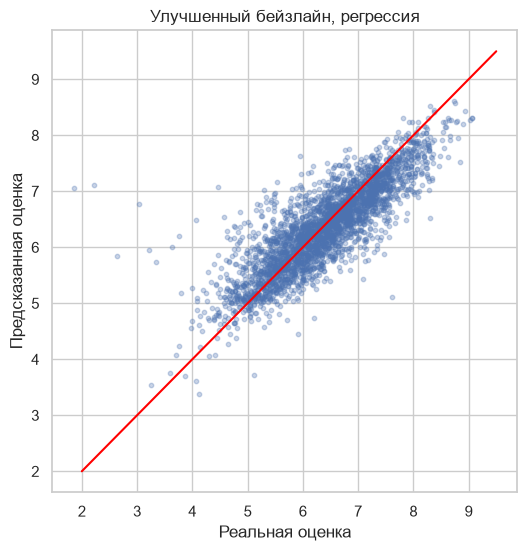

In [36]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_reg, pred_impr_reg, alpha=0.3, s=10)
plt.plot([2, 9.5], [2, 9.5], color="red")
plt.xlabel("Реальная оценка")
plt.ylabel("Предсказанная оценка")
plt.title("Улучшенный бейзлайн, регрессия")
plt.show()

Точки в основном идут вдоль диагонали, но крайние оценки модель тянет к среднему: у тайтлов с низкой оценкой (ниже 4-5) предсказания заметно выше реальных, а у самых высоких, наоборот, ниже. Так получается, потому что KNN усредняет соседей, а у очень хороших и очень плохих тайтлов похожих соседей мало.

### 3.5. Сравнение с бейзлайном

Метрики на тесте и разница:

In [37]:
compare_clf = pd.DataFrame(results_clf).T
compare_reg = pd.DataFrame(results_reg).T
compare_clf.loc["изменение"] = compare_clf.loc["sklearn улучшенный"] - compare_clf.loc["sklearn бейзлайн"]
compare_reg.loc["изменение"] = compare_reg.loc["sklearn улучшенный"] - compare_reg.loc["sklearn бейзлайн"]
display(compare_clf.round(4))
display(compare_reg.round(4))

,accuracy,f1_macro
sklearn бейзлайн,0.5834,0.3986
sklearn улучшенный,0.7182,0.6340
изменение,0.1349,0.2354


,MAE,RMSE,R2
sklearn бейзлайн,0.5186,0.6805,0.4553
sklearn улучшенный,0.3626,0.5023,0.7032
изменение,-0.1560,-0.1782,0.2479


### 3.6. Выводы

- Улучшенный бейзлайн на тесте сильно лучше исходного. В классификации macro-F1 выросла с 0.399 до 0.634, accuracy с 0.583 до 0.718. В регрессии MAE уменьшилась с 0.519 до 0.363, RMSE с 0.681 до 0.502, R2 вырос с 0.455 до 0.703.
- Больше всего помогли масштабирование и новые признаки из категориальных колонок (в классификации в первую очередь жанры), а в регрессии еще отбор признаков.
- Одни и те же гипотезы по-разному работают для двух задач: студии помогли с рейтингом, но ухудшили регрессию, а относительные признаки и отбор признаков помогли только регрессии. Для KNN важно, какие признаки участвуют в расстоянии, лишние признаки только мешают.
- В обеих задачах лучше всего манхэттенское расстояние, веса distance и k около 10.
- Хуже всего модель определяет редкие классы R и R+, их часто путает с PG-13.

## 4. Собственная реализация KNN

### 4.1. Реализация

В базовом классе MyKNN хранится обучающая выборка, считаются расстояния (евклидово или манхэттенское) и веса соседей: одинаковые (uniform) или обратно пропорциональные расстоянию (distance). Если есть соседи на нулевом расстоянии, то учитываются только они, как в sklearn. Классификатор выбирает класс с наибольшей суммой весов среди k ближайших соседей, а регрессор считает взвешенное среднее.

In [38]:
class MyKNN:
    def __init__(self, n_neighbors=5, weights="uniform", p=2):
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.p = p

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def _neighbors(self, x):
        if self.p == 1:
            dist = np.abs(self.X_train - x).sum(axis=1)
        else:
            dist = np.sqrt(((self.X_train - x) ** 2).sum(axis=1))
        idx = np.argsort(dist, kind="stable")[:self.n_neighbors]
        return idx, dist[idx]

    def _get_weights(self, dist):
        if self.weights == "uniform":
            return np.ones(len(dist))
        if np.any(dist == 0):
            return (dist == 0).astype(float)
        return 1 / dist


class MyKNNClassifier(MyKNN):
    def fit(self, X, y):
        super().fit(X, y)
        self.classes_ = np.unique(self.y_train)
        return self

    def predict(self, X):
        preds = []
        for x in np.asarray(X, dtype=float):
            idx, dist = self._neighbors(x)
            w = self._get_weights(dist)
            scores = [w[self.y_train[idx] == c].sum() for c in self.classes_]
            preds.append(self.classes_[np.argmax(scores)])
        return np.array(preds)


class MyKNNRegressor(MyKNN):
    def predict(self, X):
        preds = []
        for x in np.asarray(X, dtype=float):
            idx, dist = self._neighbors(x)
            w = self._get_weights(dist)
            preds.append(np.sum(w * self.y_train[idx]) / np.sum(w))
        return np.array(preds)

### 4.2. Обучение в условиях бейзлайна

Признаки те же, что в пункте 2, пропуски заполняю медианой (медиана по train), параметры по умолчанию: k=5, евклидово расстояние, одинаковые веса.

In [39]:
imputer_clf = SimpleImputer(strategy="median").fit(df.loc[idx_train_clf, base_features_clf])
X_train_base_clf = imputer_clf.transform(df.loc[idx_train_clf, base_features_clf])
X_test_base_clf = imputer_clf.transform(df.loc[idx_test_clf, base_features_clf])

imputer_reg = SimpleImputer(strategy="median").fit(df.loc[idx_train_reg, base_features_reg])
X_train_base_reg = imputer_reg.transform(df.loc[idx_train_reg, base_features_reg])
X_test_base_reg = imputer_reg.transform(df.loc[idx_test_reg, base_features_reg])

start = time.time()
my_base_clf = MyKNNClassifier().fit(X_train_base_clf, y_train_clf)
pred_my_base_clf = my_base_clf.predict(X_test_base_clf)
time_my_base_clf = time.time() - start

start = time.time()
my_base_reg = MyKNNRegressor().fit(X_train_base_reg, y_train_reg)
pred_my_base_reg = my_base_reg.predict(X_test_base_reg)
time_my_base_reg = time.time() - start

results_clf["своя реализация, бейзлайн"] = clf_metrics(y_test_clf, pred_my_base_clf)
results_reg["своя реализация, бейзлайн"] = reg_metrics(y_test_reg, pred_my_base_reg)

### 4.3. Сравнение с бейзлайном sklearn (пункт 2)

Чтобы сравнить время, заново обучаю бейзлайн sklearn и замеряю время обучения и предсказания.

In [40]:
start = time.time()
baseline_clf.fit(df.loc[idx_train_clf, base_features_clf], y_train_clf).predict(df.loc[idx_test_clf, base_features_clf])
time_base_clf = time.time() - start

start = time.time()
baseline_reg.fit(df.loc[idx_train_reg, base_features_reg], y_train_reg).predict(df.loc[idx_test_reg, base_features_reg])
time_base_reg = time.time() - start

display(pd.DataFrame(results_clf).T.loc[["sklearn бейзлайн", "своя реализация, бейзлайн"]].round(4))
display(pd.DataFrame(results_reg).T.loc[["sklearn бейзлайн", "своя реализация, бейзлайн"]].round(4))

print("Совпадение предсказаний: классификация", round((pred_my_base_clf == pred_base_clf).mean(), 4),
      "регрессия", round(np.isclose(pred_my_base_reg, pred_base_reg).mean(), 4))
print(f"Время, классификация: sklearn {time_base_clf:.2f} с, своя реализация {time_my_base_clf:.2f} с")
print(f"Время, регрессия: sklearn {time_base_reg:.2f} с, своя реализация {time_my_base_reg:.2f} с")

,accuracy,f1_macro
sklearn бейзлайн,0.5834,0.3986
"своя реализация, бейзлайн",0.5858,0.3996


,MAE,RMSE,R2
sklearn бейзлайн,0.5186,0.6805,0.4553
"своя реализация, бейзлайн",0.5189,0.6809,0.4546


Совпадение предсказаний: классификация 0.9842 регрессия 0.9939
Время, классификация: sklearn 0.03 с, своя реализация 4.56 с
Время, регрессия: sklearn 0.01 с, своя реализация 2.00 с


Предсказания совпали не на 100%. Проверю, у скольких объектов из теста есть ничья на границе, то есть k-й и (k+1)-й соседи находятся на одинаковом расстоянии. В таком случае от реализации зависит, какого соседа взять.

In [41]:
def count_ties(model, X_test):
    ties = 0
    for x in np.asarray(X_test, dtype=float):
        dist = np.sort(np.sqrt(((model.X_train - x) ** 2).sum(axis=1)))
        ties += dist[model.n_neighbors - 1] == dist[model.n_neighbors]
    return ties


print("Классификация:", count_ties(my_base_clf, X_test_base_clf), "из", len(X_test_base_clf))
print("Регрессия:", count_ties(my_base_reg, X_test_base_reg), "из", len(X_test_base_reg))

Классификация: 1216 из 4553


Регрессия: 55 из 3139


Метрики у своей реализации почти такие же, как у sklearn: accuracy 0.586 против 0.583, macro-F1 0.400 против 0.399, MAE 0.519 в обоих случаях. Предсказания совпали у 98.4% тайтлов в классификации и у 99.4% в регрессии.

Расхождения как раз из-за ничьих. На сырых признаках у многих тайтлов одинаковые значения (например, у тайтлов без оценки Score и Scored By заполнены одной и той же медианой), поэтому в классификации у 1216 из 4553 объектов теста 5-й и 6-й соседи на одинаковом расстоянии. Какого из них взять, sklearn и моя реализация решают по-разному, поэтому и ответы иногда разные. В регрессии таких объектов всего 55, поэтому и расхождений меньше.

По времени своя реализация сильно проигрывает: несколько секунд против сотых долей секунды у sklearn. Моя реализация считает расстояния от каждого объекта теста до всего train в цикле на питоне, а sklearn на 4-5 признаках строит KD-дерево и не перебирает все объекты.

### 4.4. Своя реализация с техниками из улучшенного бейзлайна

Беру из улучшенных пайплайнов sklearn все шаги, кроме самой модели (заполнение пропусков, масштабирование, для регрессии еще отбор признаков), они уже обучены на train, и прогоняю через них данные. В свою реализацию передаю лучшие гиперпараметры из пункта 3.

In [42]:
prep_clf = improved_clf[:-1]
prep_reg = improved_reg[:-1]

X_train_impr_clf = prep_clf.transform(df.loc[idx_train_clf, features_clf])
X_test_impr_clf = prep_clf.transform(df.loc[idx_test_clf, features_clf])
X_train_impr_reg = prep_reg.transform(df.loc[idx_train_reg, features_reg])
X_test_impr_reg = prep_reg.transform(df.loc[idx_test_reg, features_reg])
print(X_train_impr_clf.shape, X_train_impr_reg.shape)

start = time.time()
my_impr_clf = MyKNNClassifier(n_neighbors=best_knn_clf.n_neighbors, weights=best_knn_clf.weights, p=best_knn_clf.p)
pred_my_impr_clf = my_impr_clf.fit(X_train_impr_clf, y_train_clf).predict(X_test_impr_clf)
time_my_impr_clf = time.time() - start

start = time.time()
my_impr_reg = MyKNNRegressor(n_neighbors=best_knn_reg.n_neighbors, weights=best_knn_reg.weights, p=best_knn_reg.p)
pred_my_impr_reg = my_impr_reg.fit(X_train_impr_reg, y_train_reg).predict(X_test_impr_reg)
time_my_impr_reg = time.time() - start

results_clf["своя реализация, улучшенный"] = clf_metrics(y_test_clf, pred_my_impr_clf)
results_reg["своя реализация, улучшенный"] = reg_metrics(y_test_reg, pred_my_impr_reg)

(18208, 71) (12553, 30)


### 4.5. Сравнение с улучшенным бейзлайном sklearn (пункт 3)

In [43]:
start = time.time()
improved_clf.fit(df.loc[idx_train_clf, features_clf], y_train_clf).predict(df.loc[idx_test_clf, features_clf])
time_impr_clf = time.time() - start

start = time.time()
improved_reg.fit(df.loc[idx_train_reg, features_reg], y_train_reg).predict(df.loc[idx_test_reg, features_reg])
time_impr_reg = time.time() - start

display(pd.DataFrame(results_clf).T.loc[["sklearn улучшенный", "своя реализация, улучшенный"]].round(4))
display(pd.DataFrame(results_reg).T.loc[["sklearn улучшенный", "своя реализация, улучшенный"]].round(4))

print("Совпадение предсказаний: классификация", round((pred_my_impr_clf == pred_impr_clf).mean(), 4),
      "регрессия", round(np.isclose(pred_my_impr_reg, pred_impr_reg).mean(), 4))
print(f"Время, классификация: sklearn {time_impr_clf:.2f} с, своя реализация {time_my_impr_clf:.2f} с")
print(f"Время, регрессия: sklearn {time_impr_reg:.2f} с, своя реализация {time_my_impr_reg:.2f} с")

,accuracy,f1_macro
sklearn улучшенный,0.7182,0.634
"своя реализация, улучшенный",0.7182,0.634


,MAE,RMSE,R2
sklearn улучшенный,0.3626,0.5023,0.7032
"своя реализация, улучшенный",0.3626,0.5023,0.7032


Совпадение предсказаний: классификация 1.0 регрессия 1.0
Время, классификация: sklearn 0.18 с, своя реализация 6.97 с
Время, регрессия: sklearn 0.05 с, своя реализация 2.44 с


С техниками из улучшенного бейзлайна своя реализация дала точно такие же результаты, как sklearn: совпали 100% предсказаний, macro-F1 0.634, accuracy 0.718, MAE 0.363, R2 0.703. После масштабирования и с большим числом признаков одинаковые расстояния встречаются редко и на ответ не влияют.

По сравнению со своей реализацией на признаках бейзлайна macro-F1 выросла с 0.400 до 0.634, а MAE уменьшилась с 0.519 до 0.363, так же как у sklearn. То есть качество улучшилось за счет обработки данных и подбора параметров, а не из-за библиотеки.

По времени разница осталась: своя реализация работает несколько секунд, sklearn доли секунды.

## 5. Итоги

Все модели на тесте. Таблицу сохраняю в lab1_results.csv, чтобы потом использовать в итоговом сравнении в лабораторной 5.

,accuracy,f1_macro
sklearn бейзлайн,0.5834,0.3986
sklearn улучшенный,0.7182,0.6340
"своя реализация, бейзлайн",0.5858,0.3996
"своя реализация, улучшенный",0.7182,0.6340


,MAE,RMSE,R2
sklearn бейзлайн,0.5186,0.6805,0.4553
sklearn улучшенный,0.3626,0.5023,0.7032
"своя реализация, бейзлайн",0.5189,0.6809,0.4546
"своя реализация, улучшенный",0.3626,0.5023,0.7032


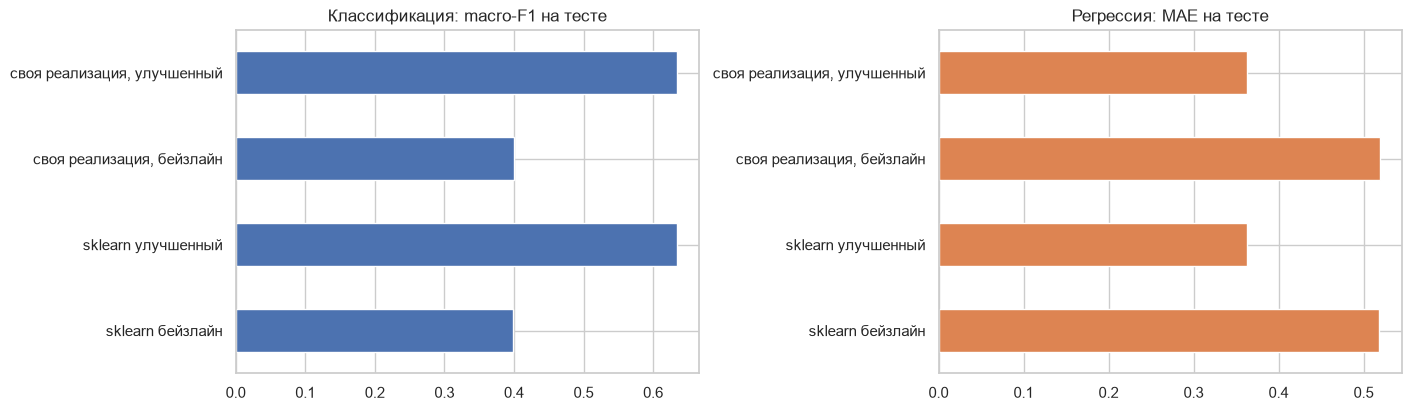

In [44]:
final_clf = pd.DataFrame(results_clf).T
final_reg = pd.DataFrame(results_reg).T
display(final_clf.round(4))
display(final_reg.round(4))

pd.concat({"классификация": final_clf, "регрессия": final_reg}).round(4).to_csv("lab1_results.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
final_clf["f1_macro"].plot.barh(ax=axes[0], color="C0")
axes[0].set_title("Классификация: macro-F1 на тесте")
final_reg["MAE"].plot.barh(ax=axes[1], color="C1")
axes[1].set_title("Регрессия: MAE на тесте")
plt.show()

Выводы:
- На сырых признаках KNN работает плохо: расстояние в основном зависит от признаков с самым большим масштабом (Members, Scored By), а редкие классы R и R+ почти не угадываются. У бейзлайна macro-F1 0.399, MAE 0.519.
- Масштабирование, логарифмы, новые признаки, отбор признаков (для регрессии) и подбор k, метрики и весов дали большой прирост: macro-F1 с 0.399 до 0.634, accuracy с 0.583 до 0.718, MAE с 0.519 до 0.363, R2 с 0.455 до 0.703. Для KNN особенно важно, какие признаки и в каком масштабе участвуют в расстоянии.
- Своя реализация дает те же результаты, что и sklearn (с улучшениями предсказания полностью совпадают), но работает в десятки-сотни раз медленнее.
- Слабые места: редкие классы R и R+ модель часто путает с PG-13, а в регрессии тянет крайние оценки к среднему.
- Результаты сохранены в lab1_results.csv для сравнения алгоритмов в лабораторной 5.